# Vẽ đường cong ROC cho mô hình hồi quy Logistic ở ví dụ giờ ôn tập

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

Số giờ ôn tập và kết quả thi (1: đỗ, 0: trượt)

In [2]:
X = np.array([0.50, 0.75, 1.00, 1.25, 1.50, 1.75, 1.75, 2.00, 2.25, 2.50,
              2.75, 3.00, 3.25, 3.50, 4.00, 4.25, 4.50, 4.75, 5.00, 5.50])
y = np.array([0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1])
w0, w1 = -4.0777, 1.5046          # nghiệm tìm được ở mục 4.1.4
p = 1 / (1 + np.exp(-(w0 + w1 * X)))   # xác suất thi đỗ

fpr, tpr, thresholds = roc_curve(y, p)
auc = roc_auc_score(y, p)
print("AUC =", auc)

AUC = 0.895


Vẽ hình và lưu ảnh.

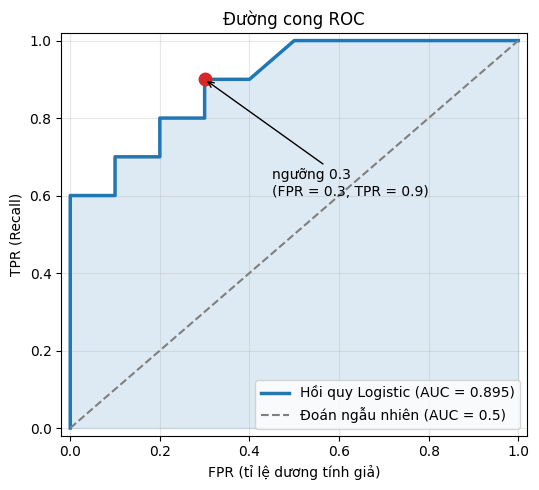

In [3]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.fill_between(fpr, tpr, alpha=0.15, color="#1F77B4")
ax.plot(fpr, tpr, color="#1F77B4", lw=2.5, label=f"Hồi quy Logistic (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], "--", color="#7F7F7F", label="Đoán ngẫu nhiên (AUC = 0.5)")
# Điểm ứng với ngưỡng 0.3: TPR = 0.9, FPR = 0.3
ax.plot(0.3, 0.9, "o", color="#D62728", ms=9)
ax.annotate("ngưỡng 0.3\n(FPR = 0.3, TPR = 0.9)", (0.3, 0.9), (0.45, 0.6),
            arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("FPR (tỉ lệ dương tính giả)"); ax.set_ylabel("TPR (Recall)")
ax.set_title("Đường cong ROC")
ax.legend(loc="lower right"); ax.grid(alpha=0.3)
ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
fig.tight_layout()
fig.savefig(IMAGES / "roc_study_hours.png", dpi=150)